# A scale-and-level complement to the PLA test

**Question:** A risk model whose volatility is 20 days old passes the FRTB P&L attribution test in every simulated year; can three
statistics computed on the same 250 days of hypothetical and risk-theoretical P&L catch it, at a false-alarm rate of 1 %?

- **Level:** 4, proposed methods
- **Prerequisites:** notebooks 01 to 07 of this topic, and the case C13 page (the desk, its generator and the PLA zones)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- say why the PLA test, a Spearman correlation and a Kolmogorov-Smirnov distance between the desk's hypothetical P&L (HPL) and the
  risk model's P&L (RTPL), cannot see a model that reads the right factors with a volatility that is weeks old;
- compute the three statistics the product proposes beside the zone, on one desk-year, and read each one;
- calibrate their thresholds on a simulated null with the engine, and measure their power on the stale model and their false
  alarms on held-out exact desks;
- read the product's committed measurement on 1,000 replications and say what the complement does and does not claim.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you.
A notebook never installs anything by itself. The next cell imports what the notebook uses and prints the versions.

In [1]:
# Import the tools, put the case's generator on the path and print the versions they run with
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.market import frtb
from riskvalidation.market import pla_complement as pc

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c13 import generator

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Case C13 is a synthetic trading desk whose truth is known: the generator `pipeline.cases.c13.generator` draws a year of daily
returns of two correlated risk factors under a volatility that wanders, the desk's HPL from them, and the RTPL a risk model
computes. Each variant plants one deficiency in the model. This notebook uses two: the exact model and the model that reads a
volatility 20 days old (`stale-volatility`), and the committed documents of both, which hold the product's own measurement on
1,000 replications. The data are generated, licence MIT, and the documents are committed under `data/derived/C13/`.

In [2]:
# Read the committed documents of case C13: the exact model and the model fed a 20-day-old volatility
C13 = ROOT / "data" / "derived" / "C13"
docs = {v: json.loads((C13 / f"{v}.json").read_text(encoding="utf-8")) for v in ("none", "stale-volatility")}
stale_doc = docs["stale-volatility"]["outputs"]
print("riskvalidation", docs["none"]["provenance"]["riskvalidation_version"])
for p in stale_doc["known_deficiency"]["parameters"]:
    print(p["name"], p["value"], p["unit"])
print("committed replications:", stale_doc["pla_complement"]["n_replications"])


riskvalidation 1.1.0
vol_lag_days 20.0 days
committed replications: 1000


## Method

The PLA test compares the two P&L series by rank (Spearman) and by distribution (Kolmogorov-Smirnov), and a desk is green when
both are close. Both are blind to *when* the scale moves: a model that applies the right shocks with an old volatility ranks the
days almost as the desk does and, over a year, draws P&L from almost the same distribution. The complement adds three statistics
on the same 250 days, computed by the engine's `riskvalidation.market.pla_complement`:

1. the Mincer-Zarnowitz regression $\mathrm{HPL}_t = a + b\,\mathrm{RTPL}_t + e_t$ and the Wald test of $(a, b) = (0, 1)$ with the
   HC3 covariance, which sees a mis-scaled or shifted model;
2. the Spearman correlation of $|\mathrm{HPL}|$ and $|\mathrm{RTPL}|$, which sees a model that misjudges the size of the day's move;
3. the Spearman correlation of the 20-day rolling means of $|\mathrm{HPL}|$ and $|\mathrm{RTPL}|$: the daily shock is shared by both
   series, so the rolling mean removes it and leaves the two scales, and a model whose volatility is $L$ days old moves its scale
   $L$ days late.

The first cell computes the zone and the three statistics on one desk-year of each model.

In [3]:
# One desk-year of each model from the case's generator: the regulatory zone and the three statistics of the complement
desks = {"exact": generator.replicate("none", 0, 13), "stale": generator.replicate("stale-volatility", 0, 13)}
for name, d in desks.items():
    zone = frtb.pla_zone(frtb.pla_spearman(d.hpl, d.rtpl), frtb.pla_ks(d.hpl, d.rtpl))
    s = pc.pla_complement_statistics(d.hpl, d.rtpl, 20)
    mz = f"Wald {s.wald:6.2f} (p {s.p_value:.4f}), slope {s.slope:.3f}"
    print(f"{name:6s} zone {zone:6s} | {mz} | Spearman |P&L| {s.spearman_abs:.4f} | rolling {s.spearman_roll:.4f}")


exact  zone green  | Wald   0.55 (p 0.7599), slope 0.997 | Spearman |P&L| 0.9465 | rolling 0.9960
stale  zone green  | Wald  10.04 (p 0.0066), slope 0.950 | Spearman |P&L| 0.9035 | rolling 0.8184


Both desks are green: the regulatory zone does not separate them. The three statistics do, in different measure. On the exact
desk the Wald statistic is 0.55 with a slope of 0.997, and the two correlations are 0.9465 and 0.9960. On the stale desk the slope
falls to 0.950 and the Wald statistic rises to 10.04, the correlation of the absolute P&L drops to 0.9035, and the rolling one drops
furthest, to 0.8184. The figure shows why the rolling statistic is the sharpest of the three.

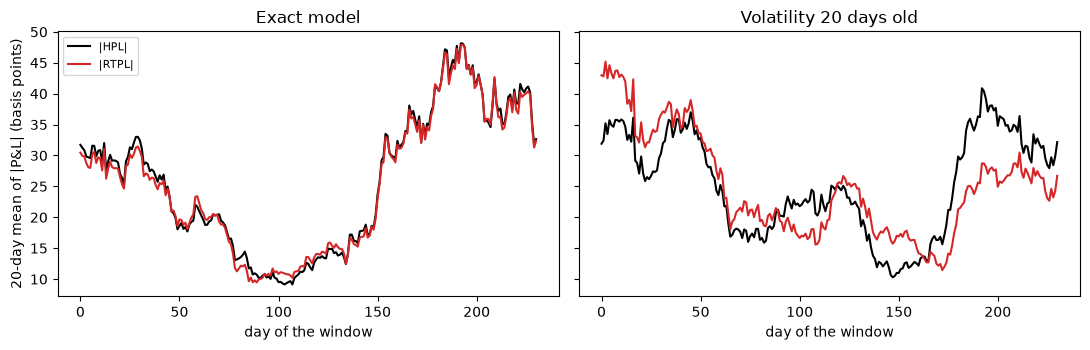

In [4]:
# Draw the 20-day rolling means of |HPL| and |RTPL| on both desks: the scale each model shows against the one it should
window = np.ones(20) / 20
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, d) in zip(axes, desks.items()):
    ax.plot(1e4 * np.convolve(np.abs(d.hpl), window, mode="valid"), color="black", label="|HPL|")
    ax.plot(1e4 * np.convolve(np.abs(d.rtpl), window, mode="valid"), color="tab:red", label="|RTPL|")
    ax.set_title("Exact model" if name == "exact" else "Volatility 20 days old")
    ax.set_xlabel("day of the window")
axes[0].set_ylabel("20-day mean of |P&L| (basis points)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


On the left the two rolling means of the exact desk lie on top of each other through the whole window: the model's scale
is the desk's scale. On the right the red line follows the black one with a delay of about four weeks, rising after the desk's
volatility has already risen and falling after it has fallen. The daily ranks of the two P&L series still agree, which is why the
zone stays green, but the scales disagree for weeks at a time, and that disagreement is what the rolling correlation measures.

A statistic needs a threshold, and none of the three has a textbook distribution under the exact model: the P&L series are
heteroscedastic and the rolling means overlap. The engine calibrates each threshold on a simulated null, the quantile of the
statistic over desk-years of the exact model, at a stated size. The complement is read at a size of 1 % for the union of the three
statistics, which the Bonferroni correction splits into a third of a percent each; the next cell also prints the thresholds at 1 %
for each statistic alone. The null is drawn under three seeds the committed run never uses, so what follows is out of sample.

In [5]:
# Calibrate the thresholds on 300 desk-years of the exact model, under three seeds the committed run never uses
null = []
for case_seed in (5013, 5014, 5015):
    for i in range(100):
        d = generator.replicate("none", i, case_seed)
        null.append(pc.pla_complement_statistics(d.hpl, d.rtpl, 20))
union = pc.pla_complement_calibrate(null, 0.01, "bonferroni")
each = pc.pla_complement_calibrate(null, 0.01, "none")
for label, th in (("union of the three at 1%", union), ("each statistic at 1%", each)):
    rule = f"Wald > {th.wald:.2f} | Spearman |P&L| < {th.spearman_abs:.4f} | rolling < {th.spearman_roll:.4f}"
    print(f"{label:28s} {rule}")


union of the three at 1%     Wald > 11.51 | Spearman |P&L| < 0.9346 | rolling < 0.9324
each statistic at 1%         Wald > 11.12 | Spearman |P&L| < 0.9382 | rolling < 0.9602


## Comparison

The method the complement is set against is the regulatory PLA test itself: its two statistics and the zone of MAR32 (green,
amber or red from the Spearman correlation and the KS distance), the only test the standard applies to the attribution of a desk.
The next cell runs it and the complement on the same 200 desk-years of the stale-volatility model, with the thresholds just
calibrated.

In [6]:
# The regulatory zone and the complement on the same 200 desk-years of the stale-volatility model
stale_stats, stale_zone = [], []
for i in range(200):
    d = generator.replicate("stale-volatility", i, 13)
    stale_stats.append(pc.pla_complement_statistics(d.hpl, d.rtpl, 20))
    stale_zone.append(frtb.pla_zone(frtb.pla_spearman(d.hpl, d.rtpl), frtb.pla_ks(d.hpl, d.rtpl)))
decisions = [pc.pla_complement_decide(s, union) for s in stale_stats]
power = {
    "PLA": np.mean([z != "green" for z in stale_zone]),
    "Wald": np.mean([x.flag_wald for x in decisions]),
    "Spearman |P&L|": np.mean([x.flag_spearman_abs for x in decisions]),
    "rolling": np.mean([x.flag_spearman_roll for x in decisions]),
    "complement (any of three)": np.mean([x.flagged for x in decisions]),
}
for name, value in power.items():
    print(f"{name:28s} {value:.3f}")


PLA                          0.000
Wald                         0.115
Spearman |P&L|               0.730
rolling                      0.990
complement (any of three)    0.995


The zone flags none of the 200 stale desk-years: on this generator the regulatory test cannot see a 20-day-old volatility at
all. The complement flags 99.5 % of them. Most of that comes from the rolling correlation alone (99.0 %); the correlation of the
absolute P&L flags 73.0 % and the Wald test 11.5 %, because a stale volatility leaves the average slope close to one. The next cell
asks how old the volatility has to be before the complement sees it, with 100 desk-years at each of four lags.

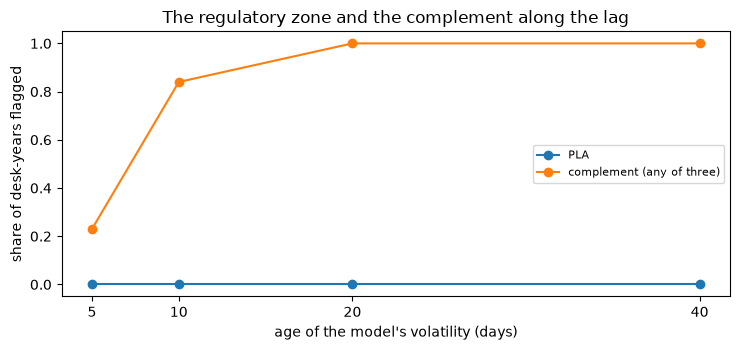

5: 0.23, 10: 0.84, 20: 1.00, 40: 1.00


In [7]:
# The lag ladder: 100 desk-years at each age of the volatility, the regulatory zone against the complement
lags = (5, 10, 20, 40)
ladder = {"PLA": [], "complement (any of three)": []}
for lag in lags:
    flags_pla, flags_any = [], []
    for i in range(100):
        d = generator.replicate("stale-volatility", i, 13, vol_lag_days=float(lag))
        flags_pla.append(frtb.pla_zone(frtb.pla_spearman(d.hpl, d.rtpl), frtb.pla_ks(d.hpl, d.rtpl)) != "green")
        flags_any.append(pc.pla_complement_decide(pc.pla_complement_statistics(d.hpl, d.rtpl, 20), union).flagged)
    ladder["PLA"].append(np.mean(flags_pla))
    ladder["complement (any of three)"].append(np.mean(flags_any))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for name, values in ladder.items():
    ax.plot(lags, values, marker="o", label=name)
ax.set_xticks(lags)
ax.set_xlabel("age of the model's volatility (days)")
ax.set_ylabel("share of desk-years flagged")
ax.set_title("The regulatory zone and the complement along the lag")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(", ".join(f"{lag}: {a:.2f}" for lag, a in zip(lags, ladder["complement (any of three)"])))


The zone stays at zero along the whole ladder, from a lag of 5 days to one of 40. The complement climbs with the lag: it
flags 0.23 of the desk-years at 5 days, 0.84 at 10 days and all of them from 20 days on. A volatility a week old is hard to tell
from the noise of one year of data, and the complement says so instead of claiming it; from two weeks on it separates the stale
model from the exact one, where the regulatory zone never does.

## Evidence

The claim, fixed in the SDD before any run: at a size of at most 1 %, the complement flags the model with a 20-day-old volatility in
at least 30 % of the replications, and the claim is refuted below 10 %. A flag rate means nothing without the false alarms that buy
it, so the next cell runs the complement, with the same thresholds, on 300 exact desk-years under the case seed (none of them in the
null) and sets the two rates side by side for each statistic and for the union.

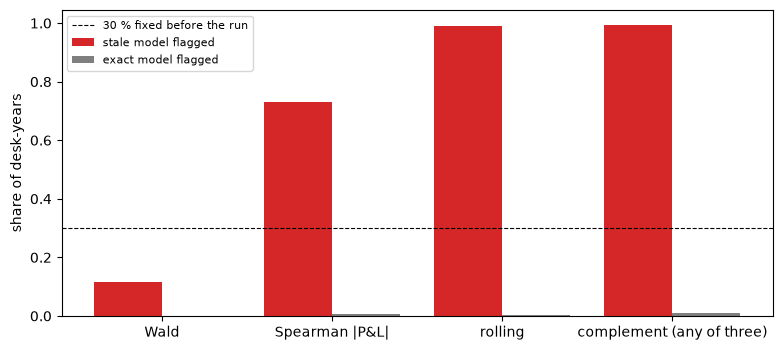

Wald                         stale model flagged 0.115 | exact model flagged 0.000
Spearman |P&L|               stale model flagged 0.730 | exact model flagged 0.007
rolling                      stale model flagged 0.990 | exact model flagged 0.003
complement (any of three)    stale model flagged 0.995 | exact model flagged 0.010


In [8]:
# Measure the claim: the false alarms on 300 held-out exact desks beside the flags on the stale desks, by statistic
held_desks = [generator.replicate("none", i, 13) for i in range(300)]
held = [pc.pla_complement_statistics(d.hpl, d.rtpl, 20) for d in held_desks]
held_dec = [pc.pla_complement_decide(s, union) for s in held]
alarms = {
    "Wald": np.mean([x.flag_wald for x in held_dec]),
    "Spearman |P&L|": np.mean([x.flag_spearman_abs for x in held_dec]),
    "rolling": np.mean([x.flag_spearman_roll for x in held_dec]),
    "complement (any of three)": np.mean([x.flagged for x in held_dec]),
}
names = list(alarms)
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(x - 0.2, [power[n] for n in names], 0.4, label="stale model flagged", color="tab:red")
ax.bar(x + 0.2, [alarms[n] for n in names], 0.4, label="exact model flagged", color="tab:gray")
ax.axhline(0.30, color="black", linestyle="--", linewidth=0.8, label="30 % fixed before the run")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("share of desk-years")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
power_label, alarms_label = "stale model flagged", "exact model flagged"
for n in names:
    print(f"{n:28s} {power_label} {power[n]:.3f} | {alarms_label} {alarms[n]:.3f}")


Every grey bar stays near or under the nominal size: the union raises 0.010 false alarms on the exact desks, the Wald test
none, the absolute correlation 0.007 and the rolling one 0.003. Every red bar but the Wald test's stands above the dashed 30 % the
claim asks for, and the union's, at 0.995, is far above it. The claim holds on this run of 200 stale and 300 exact desk-years, and
nothing was tuned to reach it: the window, the size and the correction were fixed before the null was drawn. The product's own
run is larger.

In [9]:
# The committed measurement of the product: 1,000 replications under the case seed, the null from 10,000 desk-years
block = stale_doc["pla_complement"]
fam = block["flags"]["family"]["any"]
union_label, alarms_label = "union of the three at 1%", "exact model flagged"
print(f"{union_label}: {fam['k']} / {fam['n']} = {fam['rate']:.3f} ({fam['ci_low']:.3f} to {fam['ci_high']:.3f})")
for key, row in block["flags"]["per_statistic"].items():
    print(f"  {key:14s} {row['rate']:.3f}")
held_out = docs["none"]["outputs"]["pla_complement"]["flags"]["family"]["any"]
print(f"{alarms_label}: {held_out['k']} / {held_out['n']} = {held_out['rate']:.3f}")


union of the three at 1%: 999 / 1000 = 0.999 (0.994 to 1.000)
  wald           0.142
  spearman_abs   0.767
  spearman_roll  0.999
  any            1.000
exact model flagged: 9 / 1000 = 0.009


The committed measurement reads 999 flags in 1,000 stale desk-years for the union at 1 %, an interval from 0.994 to 0.9998,
with thresholds calibrated on 10,000 null desk-years, and 9 false alarms in 1,000 exact ones (0.009). This notebook's smaller run
agrees with it within its own sampling error. What the complement does not claim: it has no regulatory standing, it is added beside
the zone and never replaces it, and it is calibrated on this generator, so a desk with another P&L process needs its own null.

## Results

**Answer:** Yes. On desk-years of the case's generator the regulatory PLA zone flags the model with a 20-day-old volatility in none of
200 desk-years, while the complement, calibrated at 1 % for the union of its three statistics, flags 0.995 of them and raises 0.010
false alarms on 300 held-out exact desk-years; the rolling correlation of the absolute P&L does almost all of the work. The product's
committed measurement on 1,000 replications reads 0.999 against 0.009. Below a lag of about ten days the complement loses power
(0.23 at 5 days), which is the limit of one year of data.

## Summary

- The PLA zone ranks and compares distributions, so it cannot see a model whose volatility lags the desk's: none of 200 stale
  desk-years were amber or red.
- The rolling correlation of the absolute P&L tracks the scale over 20 days and flags 0.990 of the stale desk-years on its own; the
  union of the three statistics flags 0.995.
- The thresholds come from a simulated null of the exact model at a stated size, and the false alarms on held-out exact desks stay
  near it (0.010 for the union).
- The complement is information beside the zone, calibrated on this generator, with no regulatory standing.

## References

- Basel Committee on Banking Supervision (2019), Minimum capital requirements for market risk, MAR32 (the P&L attribution test). https://www.bis.org/bcbs/publ/d457.htm
- Mincer, J. and Zarnowitz, V. (1969), The evaluation of economic forecasts, in J. Mincer (ed.), Economic Forecasts and Expectations, NBER.
- MacKinnon, J. G. and White, H. (1985), Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties, Journal of Econometrics 29(3), 305-325.
- riskvalidation 1.1.0, `market.pla_complement` and its page. https://github.com/fsantibanezleal/CAOS_RiskValidation/blob/main/docs/market/09_pla-complement.md